# Experiment 6: Implementation of LSTM for Sentiment Analysis

**Name:** Midhun P  
**Roll Number:** 24BAD069  
**Platform:** Google Colab  
**Dataset:** IMDB Movie Reviews  
**Aim:** To implement an LSTM neural network to classify movie reviews as Positive or Negative.

> This notebook uses the IMDB dataset provided by Keras. Its reviews are already converted into integer word IDs by the dataset loader. We decode a sample for inspection, prepare equal-length sequences with padding, train an LSTM, evaluate it, and test new reviews using the same vocabulary and preprocessing rules.

## Part A — Dataset Preparation

### Step 1: Import libraries and set parameters

In [1]:
# Enter your details before running the notebook
STUDENT_NAME = "Midhun P"
ROLL_NUMBER = "24BAD069"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

print("Student Name:", STUDENT_NAME)
print("Roll Number:", ROLL_NUMBER)
print("TensorFlow version:", tf.__version__)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

VOCAB_SIZE = 10000
MAX_LEN = 200


Student Name: Midhun P
Roll Number: 24BAD069
TensorFlow version: 2.21.0


### Step 2: Load and explore the IMDB dataset

The dataset contains reviews labeled as `0 = Negative` and `1 = Positive`. Keras provides integer-encoded reviews, so the vocabulary/tokenization has already been applied by the dataset loader.

In [2]:
(X_train_all, y_train_all), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Training reviews:", len(X_train_all))
print("Testing reviews:", len(X_test))
print("First 10 training labels:", y_train_all[:10])
print("Label meaning: 0 = Negative, 1 = Positive")

# Build a reverse vocabulary to decode a review for inspection
word_index = imdb.get_word_index()
index_word = {index + 3: word for word, index in word_index.items()}
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"
index_word[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(index_word.get(int(token), "?") for token in sequence)

print("\nSample review:")
print(decode_review(X_train_all[0])[:1000])
print("Sentiment:", "Positive" if y_train_all[0] == 1 else "Negative")

print("\nClass distribution in training data:")
print(pd.Series(y_train_all).map({0: "Negative", 1: "Positive"}).value_counts())


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
First 10 training labels: [1 0 0 1 0 0 1 0 1 0]
Label meaning: 0 = Negative, 1 = Positive
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Sample review:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the

### Step 3: Prepare sequences and create training/validation sets

Reviews are padded or truncated to `MAX_LEN` so they have equal length. A portion of the original training data is used for validation; the separate test dataset is kept for final evaluation.

In [3]:
# Pad training and test sequences to the same length
X_train_padded_all = pad_sequences(
    X_train_all, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_padded = pad_sequences(
    X_test, maxlen=MAX_LEN, padding="post", truncating="post"
)

# Use 20% of the original training set for validation
split_at = int(0.8 * len(X_train_padded_all))
X_train = X_train_padded_all[:split_at]
y_train = y_train_all[:split_at]
X_val = X_train_padded_all[split_at:]
y_val = y_train_all[split_at:]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("X_test shape:", X_test_padded.shape)
print("y_test shape:", y_test.shape)
print("\nFirst padded sequence:")
print(X_train[0][:30])


X_train shape: (20000, 200)
y_train shape: (20000,)
X_val shape: (5000, 200)
y_val shape: (5000,)
X_test shape: (25000, 200)
y_test shape: (25000,)

First padded sequence:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480]


## Part B — Implementing the LSTM Model

### Step 4: Build, compile, and display the model

- **Embedding:** converts integer word IDs into dense vectors.
- **LSTM:** learns sequential/contextual patterns in the review.
- **Dense + Sigmoid:** outputs a probability for the positive class.
- **Binary cross-entropy:** suitable loss for binary classification.
- **Adam:** optimizer used to update model weights.

In [4]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True),
    LSTM(64, dropout=0.2, recurrent_dropout=0.0),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, MAX_LEN))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

## Part C — Model Training and Performance Evaluation

### Step 5: Train the model

The notebook trains for 3 epochs by default to keep the lab run manageable. You can increase `EPOCHS` if more training is required. Training accuracy/loss and validation accuracy/loss are recorded automatically.

In [5]:
EPOCHS = 3
BATCH_SIZE = 128

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    verbose=1
)


Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 72s 437ms/step - accuracy: 0.6167 - loss: 0.6736 - val_accuracy: 0.5670 - val_loss: 0.6665
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 85s 456ms/step - accuracy: 0.7790 - loss: 0.4859 - val_accuracy: 0.8286 - val_loss: 0.3999
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 67s 429ms/step - accuracy: 0.8716 - loss: 0.3184 - val_accuracy: 0.8584 - val_loss: 0.3887


### Step 6: Display training and validation metrics

In [6]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "Epoch"
display(history_df)

print("Final training accuracy:", round(history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Final training loss:", round(history.history["loss"][-1], 4))
print("Final validation loss:", round(history.history["val_loss"][-1], 4))


,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.6167,0.673619,0.5670,0.666516
2,0.7790,0.485945,0.8286,0.399947
3,0.8716,0.318397,0.8584,0.388679


Final training accuracy: 0.8716
Final validation accuracy: 0.8584
Final training loss: 0.3184
Final validation loss: 0.3887


### Step 7: Plot accuracy vs. epoch and loss vs. epoch

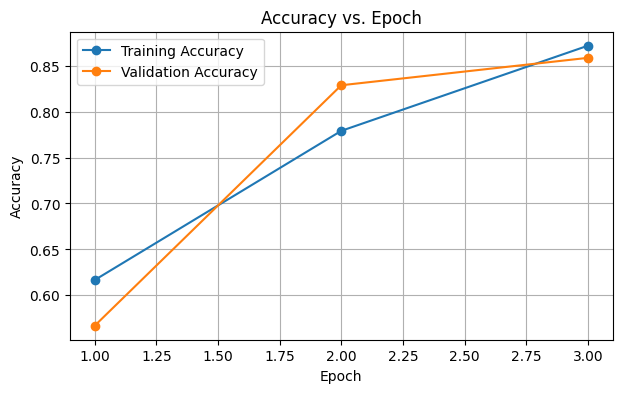

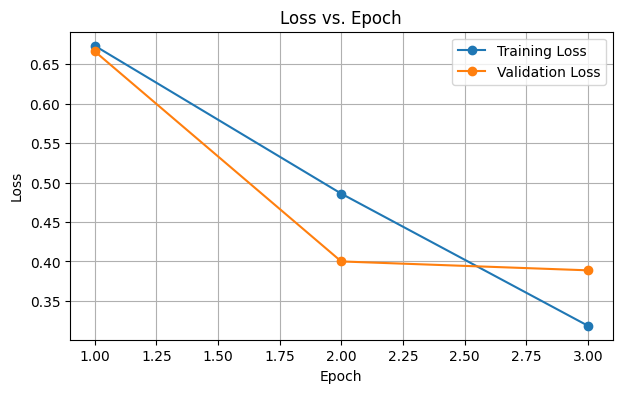

In [7]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()


### Step 8: Evaluate on the test dataset and generate a confusion matrix

Test loss:     0.4344
Test accuracy: 0.8402
Accuracy:      0.8402
Precision:     0.8514
Recall:        0.8243
F1-score:      0.8377

Classification report:
              precision    recall  f1-score   support

    Negative       0.83      0.86      0.84     12500
    Positive       0.85      0.82      0.84     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.84     25000
weighted avg       0.84      0.84      0.84     25000



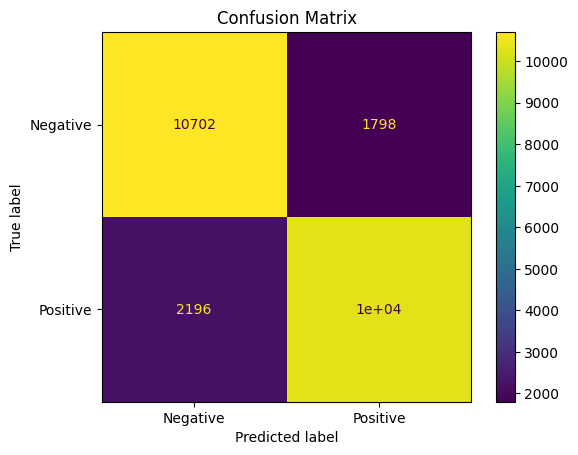

In [8]:
test_loss, test_accuracy = model.evaluate(X_test_padded, y_test, verbose=0)
probabilities = model.predict(X_test_padded, batch_size=BATCH_SIZE, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Accuracy:      {accuracy:.4f}")
print(f"Precision:     {precision:.4f}")
print(f"Recall:        {recall:.4f}")
print(f"F1-score:      {f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
display_cm.plot()
plt.title("Confusion Matrix")
plt.show()


## Part D — Sentiment Prediction for New Reviews

### Step 9: Preprocess and predict new review sentences

Because the IMDB Keras dataset uses a fixed vocabulary and integer IDs, this function uses the same word-index mapping and unknown-word handling. It then pads the sequence to the same `MAX_LEN` used during training.

In [9]:
# The original Keras IMDB vocabulary uses indices starting at 1,
# with reserved IDs 0-3. Limit words to the vocabulary used by the model.
def encode_new_review(text):
    tokens = text.lower().split()
    sequence = [1]  # <START>
    for token in tokens:
        # Basic punctuation stripping to make simple sample input more usable
        token = token.strip(".,!?;:\"'()[]{}")
        if not token:
            continue
        original_index = word_index.get(token)
        keras_index = original_index + 3 if original_index is not None else 2
        if keras_index >= VOCAB_SIZE:
            keras_index = 2  # <UNK> for words outside the chosen vocabulary
        sequence.append(keras_index)
    return pad_sequences([sequence], maxlen=MAX_LEN, padding="post", truncating="post")

def predict_sentiment(review):
    encoded = encode_new_review(review)
    probability = float(model.predict(encoded, verbose=0)[0][0])
    label = "Positive" if probability >= 0.5 else "Negative"
    return label, probability

sample_reviews = [
    ("The movie was wonderful and the acting was excellent", "Positive"),
    ("This film was boring and the story was terrible", "Negative"),
    ("I enjoyed the characters and the ending was beautiful", "Positive"),
    ("A disappointing movie with poor acting and a weak plot", "Negative")
]

rows = []
for review, expected in sample_reviews:
    predicted, probability = predict_sentiment(review)
    rows.append({
        "Review": review,
        "Expected Sentiment": expected,
        "Predicted Sentiment": predicted,
        "Positive Probability": round(probability, 4),
        "Correct?": predicted == expected
    })

prediction_df = pd.DataFrame(rows)
display(prediction_df)


,Review,Expected Sentiment,Predicted Sentiment,Positive Probability,Correct?
0,The movie was wonderful and the acting was exc...,Positive,Positive,0.8723,True
1,This film was boring and the story was terrible,Negative,Negative,0.1008,True
2,I enjoyed the characters and the ending was be...,Positive,Positive,0.8427,True
3,A disappointing movie with poor acting and a w...,Negative,Negative,0.0377,True
